# Task 2 — Electricity Demand Forecasting (PJME)

**InternSpark Business Analytics Internship | Task 2: Sales Forecasting Model**

> The assignment-provided dataset is hourly electricity consumption, not product sales. This notebook therefore forecasts electricity demand in MW. It uses the `PJME_hourly.csv` series from the supplied archive.

## Objective
Prepare the hourly series, diagnose data-quality issues, aggregate to daily average demand, fit and evaluate an ETS forecasting model, compare it with a weekly seasonal-naive benchmark, and produce a 90-day forecast with approximate prediction intervals and illustrative scenarios.

## Methodology
- Aggregate duplicate hourly timestamps by taking their mean.
- Reindex the series to a continuous hourly timeline and calculate daily mean demand.
- Interpolate missing daily values in time order; no future observations are used in the holdout evaluation.
- Reserve the final 365 days as a chronological holdout set.
- Compare additive Holt–Winters ETS with a simple weekly seasonal-naive benchmark using MAE, MAPE and RMSE.
- Refit ETS on all available daily observations and forecast 90 days ahead.
- Estimate an approximate 90% interval by resampling validation residuals. The interval is empirical and should not be interpreted as a guaranteed coverage interval.
- Show low/base/high scenarios using an illustrative ±5% demand adjustment; these are planning sensitivities, not separately fitted models.

**Important limitation:** the dataset ends in 2018. The forecast is a historical modelling exercise for the assignment and is not a current operational forecast.

## 1. Load data and inspect data quality
Upload `PJME_hourly_source.csv` when running this notebook in a fresh Colab session, or place it in the same folder as the notebook.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import ExponentialSmoothing

# In Colab, uncomment the next two lines if the CSV is not already in the session:
# from google.colab import files
# files.upload()

DATA_PATH = "PJME_hourly_source.csv"
raw = pd.read_csv(DATA_PATH)
print("Shape:", raw.shape)
print("Columns:", raw.columns.tolist())
display(raw.head())
print("Missing values:\n", raw.isna().sum())
print("Exact duplicate rows:", int(raw.duplicated().sum()))

Shape: (145366, 2)
Columns: ['Datetime', 'PJME_MW']


,Datetime,PJME_MW
0,2002-12-31 01:00:00,26498.0
1,2002-12-31 02:00:00,25147.0
2,2002-12-31 03:00:00,24574.0
3,2002-12-31 04:00:00,24393.0
4,2002-12-31 05:00:00,24860.0


Missing values:
 Datetime    0
PJME_MW     0
dtype: int64
Exact duplicate rows: 0


In [2]:
raw["Datetime"] = pd.to_datetime(raw["Datetime"], errors="coerce")
raw["PJME_MW"] = pd.to_numeric(raw["PJME_MW"], errors="coerce")
raw = raw.dropna(subset=["Datetime", "PJME_MW"]).sort_values("Datetime")
duplicate_timestamp_rows = int(raw["Datetime"].duplicated(keep=False).sum())
hourly = raw.groupby("Datetime")["PJME_MW"].mean().sort_index()
full_index = pd.date_range(hourly.index.min().floor("h"), hourly.index.max().ceil("h"), freq="h")
hourly_regular = hourly.reindex(full_index)
missing_hourly_timestamps = int(hourly_regular.isna().sum())

daily = hourly_regular.resample("D").mean()
missing_daily_before = int(daily.isna().sum())
daily = daily.interpolate(method="time", limit=3, limit_direction="both")
if daily.isna().any():
    daily = daily.interpolate(method="time").ffill().bfill()
daily.name = "Daily_Average_Demand_MW"
daily.index.name = "Date"

print(f"Duplicate-timestamp rows before aggregation: {duplicate_timestamp_rows}")
print(f"Missing hourly timestamps after regularizing the index: {missing_hourly_timestamps}")
print(f"Missing daily values before interpolation: {missing_daily_before}")
print(f"Daily observations after preparation: {len(daily):,}")
print(f"Date range: {daily.index.min().date()} to {daily.index.max().date()}")
print(f"Daily mean demand: {daily.mean():,.1f} MW")
print(f"Daily minimum: {daily.min():,.1f} MW | Daily maximum: {daily.max():,.1f} MW")

Duplicate-timestamp rows before aggregation: 8
Missing hourly timestamps after regularizing the index: 30
Missing daily values before interpolation: 0
Daily observations after preparation: 6,059
Date range: 2002-01-01 to 2018-08-03
Daily mean demand: 32,080.1 MW
Daily minimum: 19,769.0 MW | Daily maximum: 52,229.8 MW


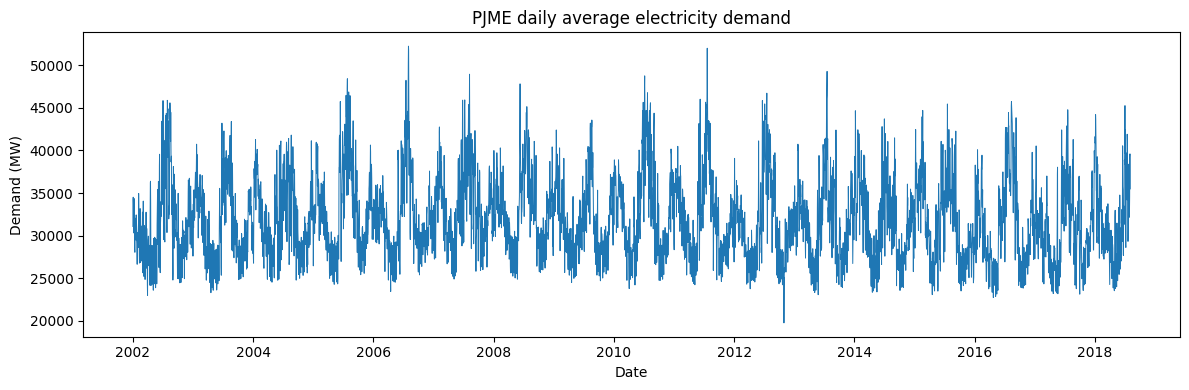

In [3]:
plt.figure(figsize=(12, 4))
plt.plot(daily.index, daily.values, linewidth=0.7)
plt.title("PJME daily average electricity demand")
plt.xlabel("Date"); plt.ylabel("Demand (MW)")
plt.tight_layout(); plt.show()

## 2. Chronological holdout evaluation
The final 365 days are held out to mimic forecasting into the future. Random splitting is avoided because it would leak future information into training.

In [4]:
test_days = 365
train, test = daily.iloc[:-test_days], daily.iloc[-test_days:]

ets = ExponentialSmoothing(
    train, trend="add", seasonal="add", seasonal_periods=7,
    initialization_method="estimated"
).fit(optimized=True, use_brute=False)
ets_pred = ets.forecast(len(test))

# Repeat the most recent observed 7-day pattern as a simple benchmark.
naive_pred = pd.Series(
    [train.iloc[-7 + (i % 7)] for i in range(len(test))],
    index=test.index, name="Weekly seasonal naive"
)

def metrics(actual, pred):
    actual = np.asarray(actual, dtype=float)
    pred = np.asarray(pred, dtype=float)
    return {
        "MAE_MW": np.mean(np.abs(actual - pred)),
        "MAPE_percent": np.mean(np.abs((actual - pred) / actual)) * 100,
        "RMSE_MW": np.sqrt(np.mean((actual - pred) ** 2))
    }

results = pd.DataFrame([
    {"Model": "ETS additive trend + weekly seasonality", **metrics(test, ets_pred)},
    {"Model": "Weekly seasonal-naive benchmark", **metrics(test, naive_pred)}
])
display(results.round(2))

,Model,MAE_MW,MAPE_percent,RMSE_MW
0,ETS additive trend + weekly seasonality,5577.32,19.23,6321.82
1,Weekly seasonal-naive benchmark,4838.78,16.18,5781.48


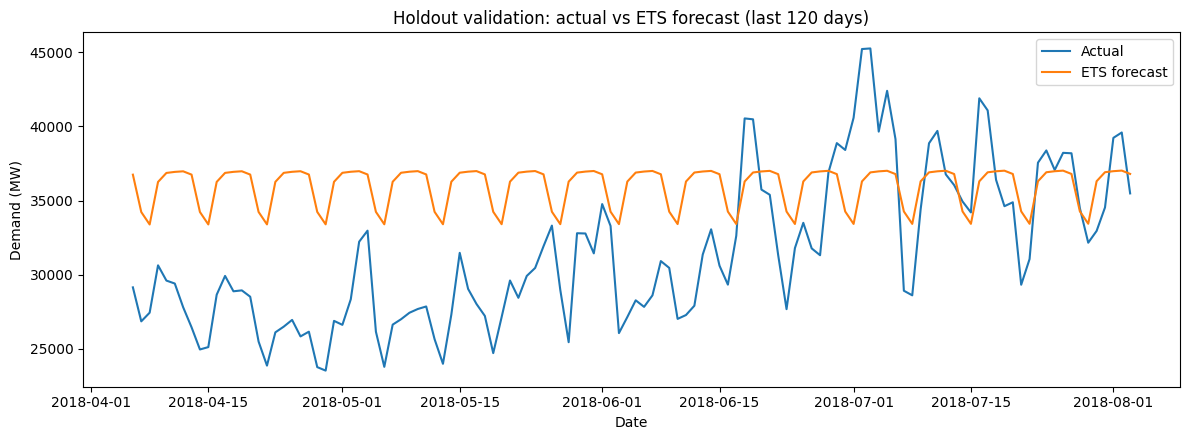

In [5]:
plt.figure(figsize=(12, 4.5))
plt.plot(test.index[-120:], test.values[-120:], label="Actual", linewidth=1.5)
plt.plot(ets_pred.index[-120:], ets_pred.values[-120:], label="ETS forecast", linewidth=1.5)
plt.title("Holdout validation: actual vs ETS forecast (last 120 days)")
plt.xlabel("Date"); plt.ylabel("Demand (MW)")
plt.legend(); plt.tight_layout(); plt.show()

## 3. Fit final model and create a 90-day forecast
The final model uses the full prepared series. The approximate prediction interval is calibrated by resampling the one-year holdout residuals. The ±5% low/high cases are explicit planning assumptions rather than probabilistic forecasts.

In [6]:
final_model = ExponentialSmoothing(
    daily, trend="add", seasonal="add", seasonal_periods=7,
    initialization_method="estimated"
).fit(optimized=True, use_brute=False)

horizon = 90
future_dates = pd.date_range(daily.index.max() + pd.Timedelta(days=1), periods=horizon, freq="D")
base_forecast = pd.Series(np.asarray(final_model.forecast(horizon)), index=future_dates)

residuals = np.asarray(test - ets_pred, dtype=float)
residuals = residuals[np.isfinite(residuals)]
rng = np.random.default_rng(42)
simulations = np.vstack([
    np.asarray(base_forecast) + rng.choice(residuals, size=horizon, replace=True)
    for _ in range(1000)
])
lower90 = np.quantile(simulations, 0.05, axis=0)
upper90 = np.quantile(simulations, 0.95, axis=0)

forecast = pd.DataFrame({
    "Date": future_dates,
    "Base_Forecast_MW": np.asarray(base_forecast),
    "Lower_90pct_Interval_MW": lower90,
    "Upper_90pct_Interval_MW": upper90,
    "Low_Demand_Scenario_MW": np.asarray(base_forecast) * 0.95,
    "High_Demand_Scenario_MW": np.asarray(base_forecast) * 1.05
})
display(forecast.head(10).round(1))
forecast.to_csv("90_day_demand_forecast.csv", index=False)

,Date,Base_Forecast_MW,Lower_90pct_Interval_MW,Upper_90pct_Interval_MW,Low_Demand_Scenario_MW,High_Demand_Scenario_MW
0,2018-08-04,33061.9,22941.0,36106.5,31408.8,34715.0
1,2018-08-05,32240.9,22303.7,36321.7,30628.8,33852.9
2,2018-08-06,35002.9,25025.2,38961.3,33252.8,36753.1
3,2018-08-07,35677.1,25594.5,38721.8,33893.3,37461.0
4,2018-08-08,35678.9,25743.1,38711.5,33895.0,37462.9
5,2018-08-09,35714.9,25595.2,38946.3,33929.2,37500.7
6,2018-08-10,35514.3,25536.6,39493.8,33738.6,37290.0
7,2018-08-11,33064.0,22979.5,36411.2,31410.8,34717.2
8,2018-08-12,32243.0,22305.8,35474.4,30630.9,33855.2
9,2018-08-13,35005.1,24884.2,38588.9,33254.8,36755.3


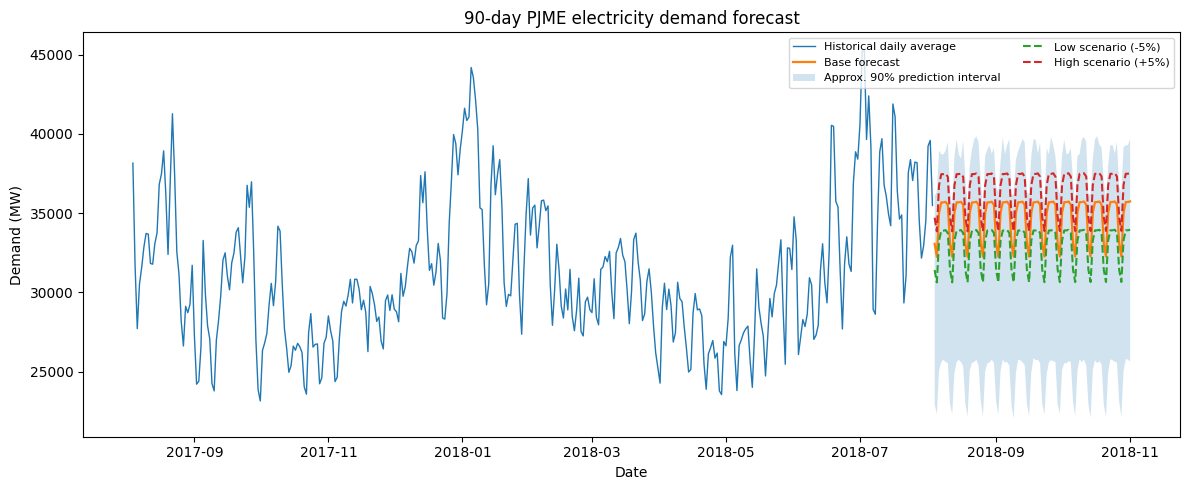

In [7]:
plt.figure(figsize=(12, 5))
plt.plot(daily.index[-365:], daily.values[-365:], label="Historical daily average", linewidth=1)
plt.plot(future_dates, base_forecast.values, label="Base forecast", linewidth=1.6)
plt.fill_between(future_dates, lower90, upper90, alpha=0.2, label="Approx. 90% prediction interval")
plt.plot(future_dates, np.asarray(base_forecast)*0.95, "--", label="Low scenario (-5%)")
plt.plot(future_dates, np.asarray(base_forecast)*1.05, "--", label="High scenario (+5%)")
plt.title("90-day PJME electricity demand forecast")
plt.xlabel("Date"); plt.ylabel("Demand (MW)")
plt.legend(ncol=2, fontsize=8); plt.tight_layout(); plt.show()

## 4. Interpretation and business actions

1. Use the base forecast as a short-term planning reference, not as a guaranteed demand path.
2. Use the prediction interval to set reserve capacity and review operational readiness on high-demand days.
3. Use the ±5% scenarios for sensitivity planning: test whether staffing, procurement, and capacity plans remain viable under lower or higher demand.
4. Monitor forecast errors on a rolling basis and retrain if MAE/MAPE deteriorate.
5. Consider richer models with temperature, holidays, and calendar effects for production use; this dataset alone does not provide weather or business drivers.

## Assumptions and limitations
- `PJME_MW` represents regional electricity demand in megawatts.
- Duplicate timestamps are averaged; daily observations are averages of available hourly readings.
- Missing daily values are time-interpolated to obtain a regular daily series.
- The model uses weekly seasonality only; annual weather-driven patterns may not be fully captured.
- The residual-bootstrap interval is approximate and assumes holdout residuals are informative about future errors.
- The ±5% scenarios are illustrative, not statistical confidence bounds.
- The data ends in 2018, so this is a historical forecasting exercise rather than a current forecast.